# 06. Flux-ramp IQ response, 1 kHz to 2 MHz

A sawtooth flux ramp moves the SQUID through about one flux quantum per period, so the transmitted probe tone traces a
loop in the IQ plane, and the reset at the end of every period is the fastest thing the channel has to follow. This
notebook reproduces Sec. V B of the paper (Figs. 8-10 and Table III): resonator 2 of the NIST chip was read out at a
fixed probe tone while the ramp ran at 28 rates from 1 kHz to 2 MHz, and every record is compared with the
coupled-mode simulation driven by the ramp through the measured transfer function $H(f)$ of the bias line. The readout
chain is calibrated once, on the 1 kHz record; every other rate is a prediction in which nothing is adjusted but a
time shift, because the digitizer was not triggered on the ramp. Data: the IQ records
`data/flux_ramps_2026-09-26/ramp_<rate>kHz.npz`, the same-day configuration `configs/nist_res2_2026-09-26.toml`, the
bias-line poles `data/flux_line_2026-10-02/flux_line_poles.npz`, and the ramp amplitude and line attenuation recorded
by notebooks `03` and `05` (the paper's values if those have not been run). The notebook runs in about a minute and a
half, most of it spent in some seventy simulations of one ramp period each.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import time
from umux_cmt.analysis import ramps

CONFIG = CONFIGS / "nist_res2_2026-09-26.toml"
POLES = DATA / "flux_line_2026-10-02" / "flux_line_poles.npz"
RAMP_DIR = DATA / "flux_ramps_2026-09-26"

F_PROBE = 5515.8e6                                     # Hz, the probe tone logged with the records
P_CHIP = -26 + store.value("Atten", default=-62.9)     # dBm at the chip: -26 dBm at the fridge input + attenuation (05)
RAMP_AMP = store.value("RampAmpPhi", default=0.946)    # Phi0 per ramp period, measured at the source (03)

## 1. The device and the fixed inputs

Everything the simulation needs is fixed before any IQ record is looked at: the device, with resonator and SQUID
parameters fitted to the VNA flux sweep taken two hours before the records (notebook `01`); the logged probe tone; the
probe power at the chip, i.e. the fridge-input power plus the attenuation fitted to the VNA power sweep in `05`; the ramp
amplitude measured at the ramp source and the poles of $H(f)$ from a two-port measurement of the bias line (both `03`).
The probe sits 111 kHz above the bare resonance $f_0$, and the resonance, which swings by about 1 MHz over a flux
quantum, crosses it twice per period of the ramp.

In [2]:
device = uc.load_config(CONFIG)
ch = device[0]
Mfr = ch.line("FluxRamp").M
tf = uc.FluxLineTF.from_file(POLES)

print(device.summary())
print(f"\n{'probe tone':<26}{F_PROBE / 1e6:10.3f} MHz   ({(F_PROBE - ch.f0) / 1e3:+.0f} kHz from f0)")
print(f"{'linewidth f0/Qr':<26}{ch.linewidth / 1e3:10.0f} kHz")
print(f"{'ring-up time 2Qr/w0':<26}{ch.ring_up_time * 1e9:10.0f} ns")
print(f"{'probe power at the chip':<26}{P_CHIP:10.1f} dBm")
print(f"{'ramp amplitude':<26}{RAMP_AMP:10.3f} Phi0  = {RAMP_AMP * uc.Phi0 / Mfr * 1e6:.1f} uA in the coil "
      f"(Mfr = {Mfr * 1e12:.2f} pH)")
modes = ", ".join(f"{f / 1e6:.2f} MHz (Q {Q:.1f}, {tau * 1e9:.0f} ns)" for f, Q, tau in tf.mode_table())
print(f"{'bias-line modes':<26}{modes}")

nist_res2_2026-09-26: 1 channel(s), Z0 = 50 Ohm
 ch   f0 (MHz)      Qr      Qc        Qi   alpha   lamb  Mc (pH)  BW (kHz)
  0   5515.689    9515   10475    103803  -0.086  0.318     3.69       580

probe tone                  5515.800 MHz   (+111 kHz from f0)
linewidth f0/Qr                  580 kHz
ring-up time 2Qr/w0              549 ns
probe power at the chip        -88.9 dBm
ramp amplitude                 0.946 Phi0  = 135.8 uA in the coil (Mfr = 14.41 pH)
bias-line modes           4.53 MHz (Q 5.6, 395 ns), 14.02 MHz (Q 6.2, 142 ns), 22.88 MHz (Q 11.3, 157 ns), 33.89 MHz (Q 7.4, 70 ns)


The resonator rings up in 549 ns and the line's dominant mode decays in 395 ns: a 1 kHz ramp, a millisecond per
period, is slow on both scales; a 1 MHz ramp is not.

## 2. The ramp the SQUID sees

The source produces an ideal sawtooth that rises by the ramp amplitude over one period and drops back at the reset. The
bias line filters it, $\Phi_\mathrm{coil}(f) = H(f)\,\Phi_\mathrm{source}(f)$ with $H(f) = \prod_k (1 - if/p_k)^{-1}$
(Eq. 30); since $H(0) = 1$ the slope and the DC level pass unchanged (so the flux at the reset can be added after the
filter), while every reset makes the coil current overshoot and ring at 4.53 MHz. `FluxLineTF.apply_periodic`
multiplies the harmonics of one period by $H(f)$, which is the steady state of a line driven for ever.

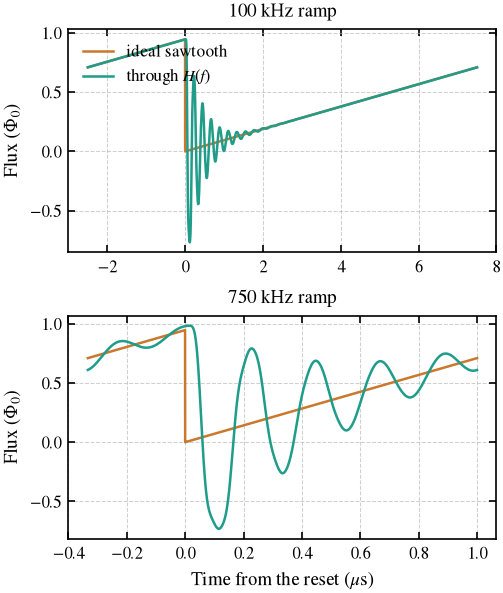

In [3]:
def ramp_flux(rate, use_tf, phi_reset=0.0):
    "Ramp-line flux in Phi0 against time, reset at t = 0: the ideal sawtooth, or the sawtooth through H(f)."
    source = uc.signals.sawtooth(rate, amplitude=RAMP_AMP)
    ramp = tf.apply_periodic(source, 1 / rate) if use_tf else source
    return lambda t: phi_reset + ramp(t)


fig, axes = plt.subplots(2, 1, figsize=(SINGLE, 4))
for ax, rate in zip(axes, (100e3, 750e3)):
    t = np.linspace(-0.25, 0.75, 4000) / rate
    ax.plot(t * 1e6, ramp_flux(rate, False)(t), color=MODEL_IDEAL, label="ideal sawtooth")
    ax.plot(t * 1e6, ramp_flux(rate, True)(t), color=MODEL_TF, label="through $H(f)$")
    ax.set_title(f"{rate / 1e3:g} kHz ramp")
    ax.set_ylabel(r"Flux ($\Phi_0$)")
    grid(ax)
axes[0].legend(loc="upper left")
axes[1].set_xlabel(r"Time from the reset ($\mu$s)")
save(fig, "06_ramp_through_line", RESULTS / "figures")
plt.show()

At 100 kHz the coil flux dips about $0.75\,\Phi_0$ below the reset value and the ringing is over within the first fifth
of the period; at 750 kHz it lasts the whole 1.3 $\mu$s period and the coil never follows the sawtooth.

## 3. Simulating one ramp period

The coil current is the ramp flux times $\Phi_0/M_\mathrm{fr}$; the device turns it into the instantaneous detuning
$\Delta(t, |a|^2)$, including the RF dressing at the energy stored at that moment, and `uc.simulate` integrates the
equation of motion (Eq. 23). The solver starts 5 $\mu$s (about ten ring-up times) before the reset from the static
steady state and returns the following period, which is the steady state of the periodically driven system; the output
grid is 10 ns or 2000 points per period, whichever is finer, and the internal step is capped at 20 ns and at 1/500 of
the period, so the 4.5 MHz ringing is resolved. In this step the ramp starts from zero flux; the flux at the reset of
the measurement is calibrated in Step 5.

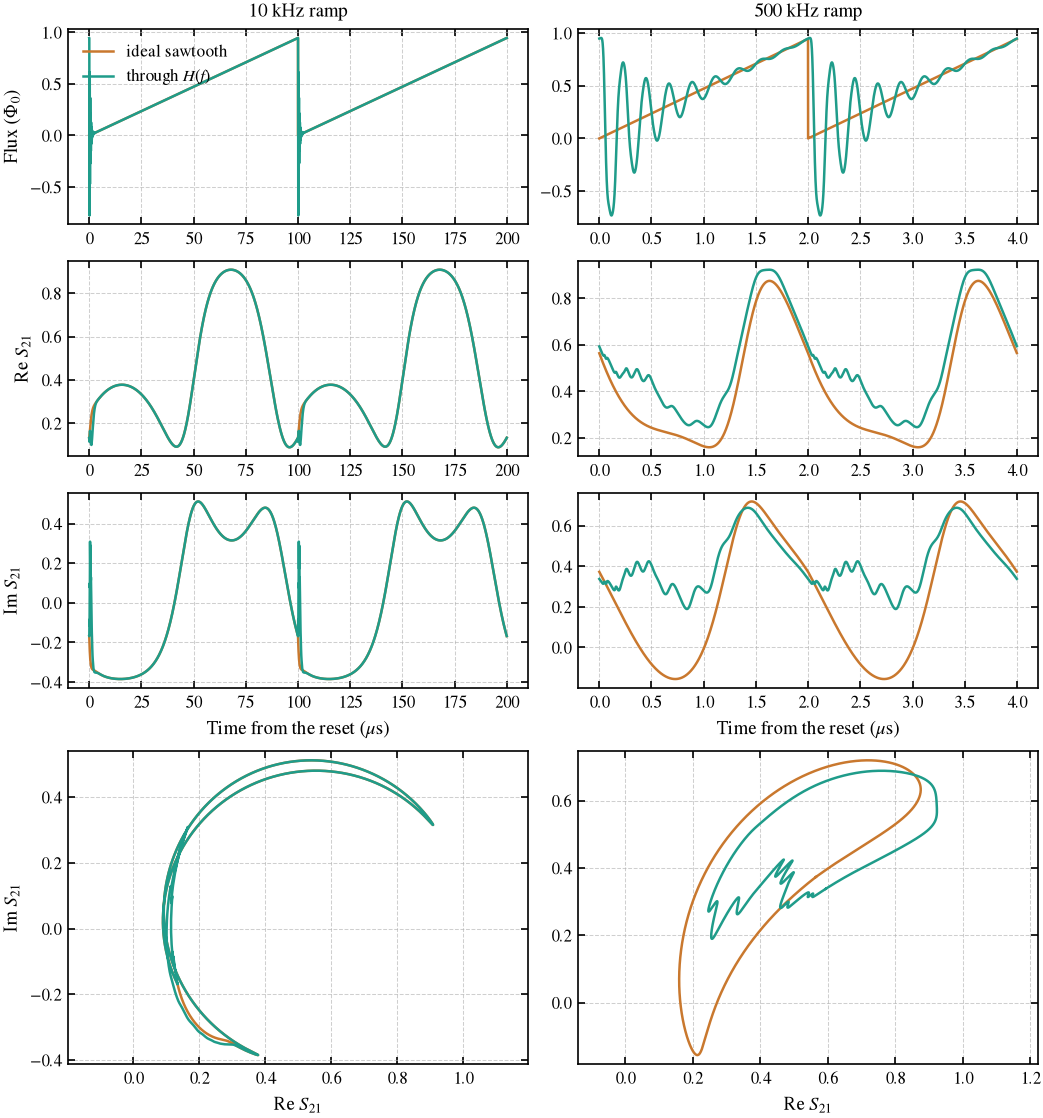

In [4]:
def simulate(rate, use_tf, phi_reset=0.0):
    "One ramp period of S21, reset at t = 0, after 5 us of settling from the static steady state."
    T = 1 / rate
    n_out = max(2000, int(np.ceil(T / 1e-8)))
    t = np.arange(n_out) / n_out * T
    I_coil = uc.signals.flux_to_current(ramp_flux(rate, use_tf, phi_reset), Mfr, uc.Phi0)
    return uc.simulate(device, F_PROBE, P_CHIP, t, flux_ramp_current_func=I_coil,
                       settle=5e-6, max_step=min(20e-9, T / 500))


DRIVES = [(False, MODEL_IDEAL, "ideal sawtooth"), (True, MODEL_TF, "through $H(f)$")]

fig, axes = plt.subplots(4, 2, figsize=(DOUBLE, 7.5), gridspec_kw={"height_ratios": [1, 1, 1, 1.6]})
for col, rate in zip(axes.T, (10e3, 500e3)):
    T = 1 / rate
    for use_tf, color, label in DRIVES:
        res = simulate(rate, use_tf)
        t2, s21 = np.r_[res.t, res.t + T], np.tile(res.s21, 2)      # two periods: the steady state repeats
        col[0].plot(t2 * 1e6, ramp_flux(rate, use_tf)(t2), color=color, label=label)
        col[1].plot(t2 * 1e6, s21.real, color=color)
        col[2].plot(t2 * 1e6, s21.imag, color=color)
        col[3].plot(res.s21.real, res.s21.imag, color=color)
    col[0].set_title(f"{rate / 1e3:g} kHz ramp")
    col[2].set_xlabel(r"Time from the reset ($\mu$s)")
    col[3].set_xlabel(r"Re $S_{21}$")
    col[3].set_aspect("equal", "datalim")
for ax, label in zip(axes[:, 0], (r"Flux ($\Phi_0$)", r"Re $S_{21}$", r"Im $S_{21}$", r"Im $S_{21}$")):
    ax.set_ylabel(label)
axes[0, 0].legend(loc="upper left")
for ax in axes.flat:
    grid(ax)
save(fig, "06_simulated_response", RESULTS / "figures")
plt.show()

At 10 kHz the two drives give the same response except in the first microseconds after the reset, where the ringing
coil flux sweeps the resonance back and forth across the probe. At 500 kHz the line rings through the whole 2 $\mu$s
period and the two drives trace different loops.

## 4. The measured records, folded

Each record holds 20 ramp periods of the demodulated probe tone $z = I + iQ$ at 40 MS/s, in volts. `ramps.fold_record`
averages all periods into one, in bins of one sample or 2000 bins per period, whichever is coarser, and gives each bin
the mean phase $u \in [0, 1)$ of its samples; the digitizer was not triggered, so $u = 0$ is the start of the record,
not the reset. The 1 kHz ramp ran 0.08% slow, which would smear its reset over 16 $\mu$s if it were folded at exactly
1 kHz, so its period is measured from the reset bursts instead (`from_resets=True`: the largest jump in each period and a
straight line through their positions), which also puts its $u = 0$ at the reset.

In [5]:
records = {}
for path in RAMP_DIR.glob("ramp_*kHz.npz"):
    rec = uc.load_record(path)
    records[rec.rate] = rec
rates = sorted(records)
meas = {rate: ramps.fold_record(rec.z, rec.fs, rec.rate, from_resets=(rate == 1e3)) for rate, rec in records.items()}

rec_1k = records[1e3]
period_1k, first_1k = ramps.reset_period(rec_1k.z, rec_1k.fs, rec_1k.rate)
print(f"{len(rates)} records; 1 kHz: {period_1k:.1f} samples per period instead of {rec_1k.fs / 1e3:.0f}, "
      f"true rate {rec_1k.fs / period_1k:.2f} Hz, first reset at sample {first_1k:.0f}\n")

rows = [f"{rate / 1e3:8g} {records[rate].fs / rate:9.1f} {len(meas[rate][0]):6d}" for rate in rates]
half = (len(rows) + 1) // 2
print(f"{'kHz':>8} {'samples':>9} {'bins':>6}" + 4 * " " + f"{'kHz':>8} {'samples':>9} {'bins':>6}")
for left, right in zip(rows[:half], rows[half:] + [""]):
    print(left + 4 * " " + right)

28 records; 1 kHz: 40031.8 samples per period instead of 40000, true rate 999.21 Hz, first reset at sample 22278

     kHz   samples   bins         kHz   samples   bins
       1   40000.0   2000         200     200.0    200
      10    4000.0   2000         250     160.0    160
      20    2000.0   2000         300     133.3    133
      40    1000.0   1000         350     114.3    114
      50     800.0    800         400     100.0    100
      60     666.7    666         450      88.9     88
      70     571.4    571         500      80.0     80
      80     500.0    500         600      66.7     66
      90     444.4    444         700      57.1     57
     100     400.0    400         800      50.0     50
     110     363.6    363         900      44.4     44
     120     333.3    333        1000      40.0     40
     140     285.7    285        1500      26.7     26
     150     266.7    266        2000      20.0     20


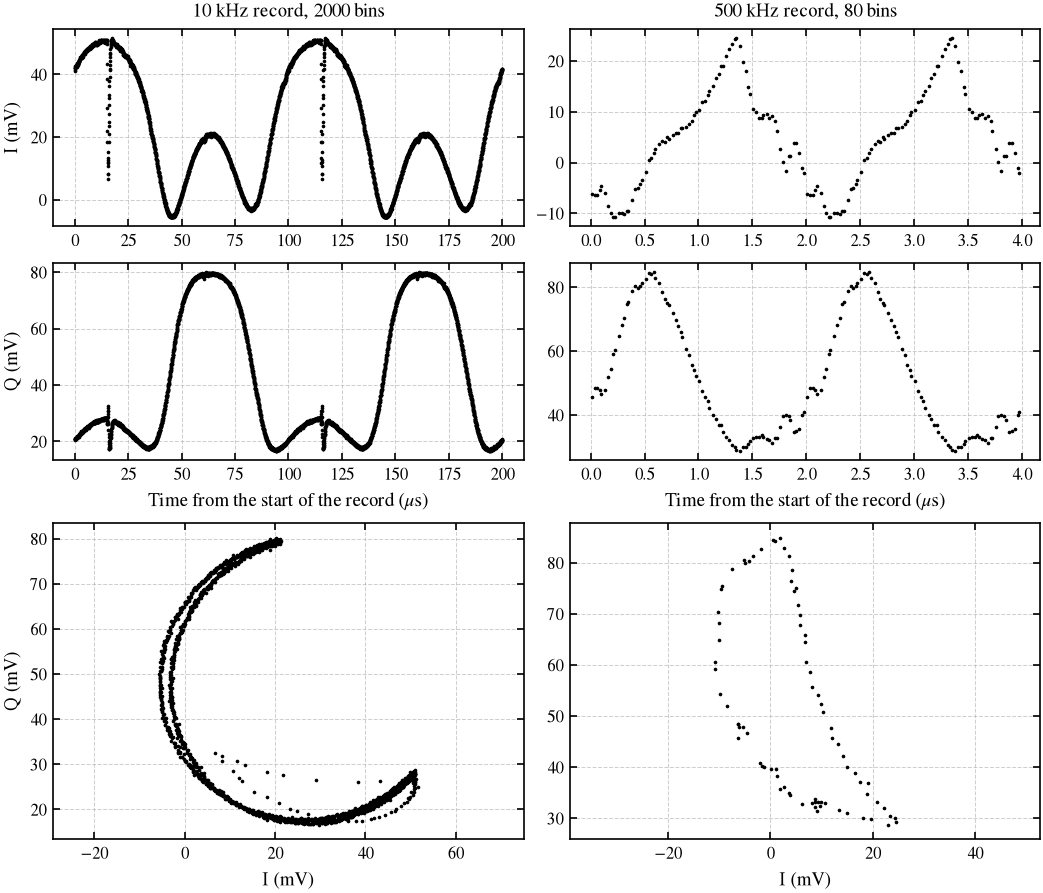

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(DOUBLE, 6), gridspec_kw={"height_ratios": [1, 1, 1.6]})
for col, rate in zip(axes.T, (10e3, 500e3)):
    u, z = meas[rate]
    t2, z2 = np.r_[u, u + 1] / rate, np.tile(z, 2)
    col[0].plot(t2 * 1e6, z2.real * 1e3, ".", color=MEASURED, ms=1.5)
    col[1].plot(t2 * 1e6, z2.imag * 1e3, ".", color=MEASURED, ms=1.5)
    col[2].plot(z.real * 1e3, z.imag * 1e3, ".", color=MEASURED, ms=1.5)
    col[0].set_title(f"{rate / 1e3:g} kHz record, {len(u)} bins")
    col[1].set_xlabel(r"Time from the start of the record ($\mu$s)")
    col[2].set_xlabel("I (mV)")
    col[2].set_aspect("equal", "datalim")
for ax, label in zip(axes[:, 0], ("I (mV)", "Q (mV)", "Q (mV)")):
    ax.set_ylabel(label)
for ax in axes.flat:
    grid(ax)
save(fig, "06_folded_records", RESULTS / "figures")
plt.show()

## 5. Calibration on the 1 kHz record (Fig. 8, Table III)

The simulation gives $S_{21}$ while the digitizer records volts, so the measurement model is
$z(u) = A\,S_{21}(u) + B$ (Eq. 31), with $u$ the phase from the reset, $A$ the complex gain of the readout chain (one
rotation and scaling of the IQ plane) and $B$ the demodulator's DC offset. The third unknown is $\Phi_\mathrm{reset}$,
the ramp-line flux at the reset, which absorbs the DC level of the ramp source and any change of the trapped flux since
the VNA sweep. These five real numbers ($\Phi_\mathrm{reset}$, $|A|$, $\arg A$, $\mathrm{Re}\,B$, $\mathrm{Im}\,B$) are
the only quantities fitted to IQ data, and they are fitted to this one record.

At 1 kHz the ramp takes a millisecond to sweep $0.946\,\Phi_0$, so apart from the first microseconds after the reset the
resonator is in the steady state for the instantaneous flux, and setting $\dot a = 0$ in the equation of motion gives
the quasi-static response $S_{21}(\Phi)$, with the RF dressing iterated to self-consistency (`uc.static_response`
tabulates it once on a flux grid, so each evaluation is an interpolation). For a trial $\Phi_\mathrm{reset}$ the model
$S_{21}(\Phi_\mathrm{reset} + 0.946\,u)$ is evaluated at the measured phases and $A$, $B$ follow by linear least
squares (`ramps.fit_gain_offset`); 4000 trials over one flux quantum locate $\Phi_\mathrm{reset}$. At that value the full
model, the CMT driven through $H(f)$ exactly as at every other rate, is simulated once (about 8 s) and $A$ and $B$ are
refitted against it. Residuals, here and below, are the rms of $|z_\mathrm{meas} - z_\mathrm{model}|$ in units of the
rms excursion of the 1 kHz trace from its mean.

In [7]:
static = uc.static_response(device, F_PROBE, P_CHIP)          # quasi-static S21 against the ramp-line flux
u_1k, z_1k = meas[1e3]
excursion = ramps.rms_excursion(z_1k)


def calibrate_static(phi_reset):
    "Gain, offset and residual of the quasi-static model at a trial reset flux, on the 1 kHz record."
    A, B, z_fit = ramps.fit_gain_offset(static(phi_reset + RAMP_AMP * u_1k), z_1k, return_fit=True)
    return A, B, ramps.rms_distance(z_1k, z_fit, excursion)


scan = np.arange(0, 1, 1 / 4000)
errs = np.array([calibrate_static(phi)[2] for phi in scan])
PHI_RESET = scan[np.argmin(errs)]

t0 = time.perf_counter()
sim_cal = simulate(1e3, True, PHI_RESET)                       # the full model at the scanned reset flux
dt_cal = time.perf_counter() - t0
u_cal = sim_cal.t * 1e3                                        # phase from the reset
A, B, z_fit = ramps.fit_gain_offset(ramps.periodic_phase_interpolant(u_cal, sim_cal.s21)(u_1k), z_1k, return_fit=True)
err_1k = ramps.rms_distance(z_1k, z_fit, excursion)

print(f"{'flux at the reset':<24}{PHI_RESET:9.4f} Phi0  (quasi-static residual at the scan minimum {errs.min():.3f})")
print(f"{'gain |A|':<24}{abs(A) * 1e3:9.2f} mV")
print(f"{'gain arg A':<24}{np.angle(A):9.3f} rad")
print(f"{'offset B':<24}{B.real * 1e3:9.2f} {B.imag * 1e3:+.2f}j mV")
print(f"{'1 kHz excursion, rms':<24}{excursion * 1e3:9.1f} mV")
print(f"{'1 kHz residual':<24}{err_1k:9.3f}       (full model through H(f), simulated in {dt_cal:.1f} s)")

far = (u_1k > 0.005) & (u_1k < 0.995)                          # bins more than 5 us from the reset
z_qs_fit = ramps.fit_gain_offset(static(PHI_RESET + RAMP_AMP * u_1k), z_1k, return_fit=True)[2]
print(f"\nmore than 5 us from the reset: quasi-static {ramps.rms_distance(z_1k[far], z_qs_fit[far], excursion):.3f}, "
      f"full model {ramps.rms_distance(z_1k[far], z_fit[far], excursion):.3f}")

store.record("IQPhiReset", PHI_RESET, "{:.3f}", "ramp-line flux at the reset, Phi0, from the 1 kHz scan (06)")
store.record("IQGainMag", abs(A) * 1e3, "{:.2f}", "readout gain |A|, mV (06)")
store.record("IQGainArg", np.angle(A), "{:.3f}", "readout gain phase arg A, rad (06)")
store.record("IQOffRe", B.real * 1e3, "{:.2f}", "demodulator offset Re B, mV (06)")
store.record("IQOffIm", B.imag * 1e3, "{:.2f}", "demodulator offset Im B, mV (06)")
store.record("IQExcursion", excursion * 1e3, "{:.1f}", "rms excursion of the 1 kHz trace, mV (06)")
store.record("IQResCal", err_1k, "{:.3f}", "1 kHz residual of the calibrated full model, units of the excursion (06)")
print("recorded:", ", ".join(f"{k} {store.text(k)}" for k in
                             ("IQPhiReset", "IQGainMag", "IQGainArg", "IQOffRe", "IQOffIm", "IQExcursion", "IQResCal")))

flux at the reset          0.1845 Phi0  (quasi-static residual at the scan minimum 0.051)
gain |A|                    68.96 mV
gain arg A                  1.220 rad
offset B                    18.30 +13.01j mV
1 kHz excursion, rms         30.3 mV
1 kHz residual              0.038       (full model through H(f), simulated in 7.5 s)

more than 5 us from the reset: quasi-static 0.037, full model 0.037
recorded: IQPhiReset 0.184, IQGainMag 68.96, IQGainArg 1.220, IQOffRe 18.30, IQOffIm 13.01, IQExcursion 30.3, IQResCal 0.038


The scan has one deep minimum; the next local minimum, half a flux quantum away, is sixteen times worse, so the 1 kHz
record pins $\Phi_\mathrm{reset}$ firmly. The full model lowers the residual from 0.051 to 0.038, and all of the gain is
at the reset: more than 5 $\mu$s away the two models fit equally well, and only the full model contains the reset
transient. The remaining 3.8% is in sample and sets the floor of the whole comparison: it measures how well the static
device model describes this channel at this probe tone.

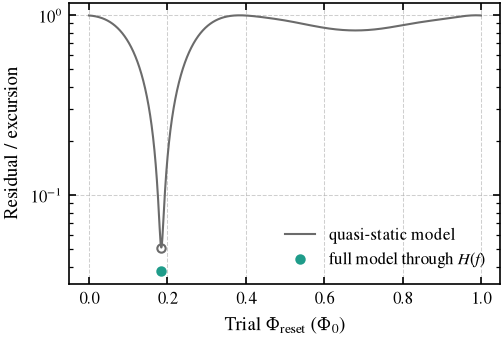

In [8]:
fig, ax = plt.subplots(figsize=(SINGLE, 2.3))
ax.semilogy(scan, errs, color=GRAY, lw=1.0, label="quasi-static model")
ax.plot(PHI_RESET, errs.min(), "o", color=GRAY, mfc="none", ms=4)
ax.plot(PHI_RESET, err_1k, "o", color=MODEL_TF, ms=4, label="full model through $H(f)$")
ax.set_xlabel(r"Trial $\Phi_\mathrm{reset}$ ($\Phi_0$)")
ax.set_ylabel("Residual / excursion")
ax.legend(loc="lower right")
grid(ax)
save(fig, "06_reset_flux_scan", RESULTS / "figures")
plt.show()

The calibrated model over one and a half periods, in the style of Fig. 8: the flux drive in both versions, the measured
$I$ and $Q$ with the full model, and the residual. Time is in ramp periods from the reset, so the same plotting function
serves every rate below; `three_periods` only repeats one folded period for the plot.

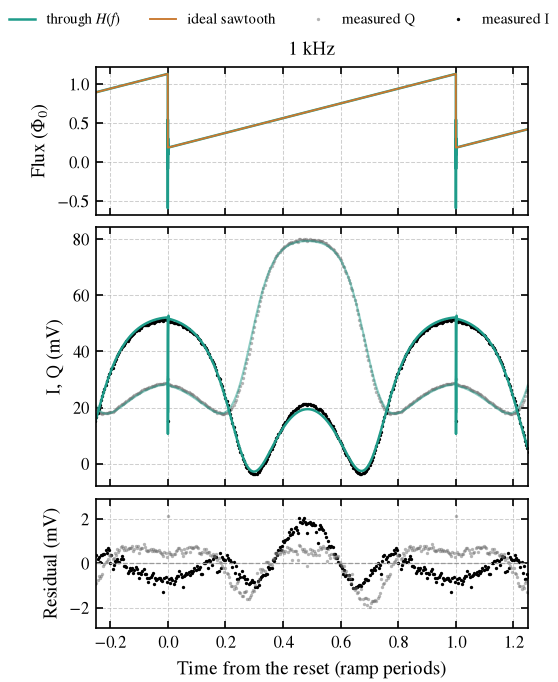

In [9]:
WINDOW = (-0.25, 1.25)                     # ramp periods from the reset shown in the trace figures
HEIGHTS = {"height_ratios": [0.8, 1.4, 0.7]}


def three_periods(q, y):
    "Repeat one period (phase q in [0, 1)) on [-1, 2), sorted in phase."
    order = np.argsort(q)
    return np.concatenate([q[order] - 1, q[order], q[order] + 1]), np.tile(y[order], 3)


def trace_column(col, rate, q_meas, z_meas, q, z_tf, flux_tf, flux_ideal, z_ideal=None):
    "Flux, I/Q and residual (against the H(f) model) on the three axes of col. Returns the residual scale in mV."
    col[0].plot(*three_periods(q, flux_tf), color=MODEL_TF, label="through $H(f)$")
    col[0].plot(*three_periods(q, flux_ideal), color=MODEL_IDEAL, lw=0.9, label="ideal sawtooth")
    step = max(1, len(q_meas) // 250)                          # draw at most ~250 measured points per period
    dots = dict(ls="none", marker="o", ms=1.6, mew=0)
    x, z = three_periods(q_meas[::step], z_meas[::step])
    col[1].plot(x, z.imag * 1e3, color=GRAY, alpha=0.5, label="measured Q", **dots)
    col[1].plot(x, z.real * 1e3, color=MEASURED, label="measured I", **dots)
    models = [(z_ideal, MODEL_IDEAL)] if z_ideal is not None else []
    for z_model, color in models + [(z_tf, MODEL_TF)]:
        x, z = three_periods(q, z_model)
        col[1].plot(x, z.imag * 1e3, color=color, lw=1.0, alpha=0.5)
        col[1].plot(x, z.real * 1e3, color=color, lw=1.2)
    resid = z_meas - ramps.periodic_phase_interpolant(q, z_tf)(q_meas)
    x, r = three_periods(q_meas[::step], resid[::step])
    col[2].plot(x, r.real * 1e3, color=MEASURED, **dots)
    col[2].plot(x, r.imag * 1e3, color=GRAY, alpha=0.5, **dots)
    col[2].axhline(0, color=ZERO, ls="--", lw=0.6)
    col[0].set_title(f"{rate / 1e3:g} kHz")
    col[2].set_xlim(*WINDOW)
    for ax in col:
        grid(ax)
    return 1.5 * np.percentile(np.abs(np.r_[resid.real, resid.imag]), 99) * 1e3


def finish(fig, axes):
    "Row labels and one legend for a figure of trace columns."
    for ax, label in zip(axes[:, 0], (r"Flux ($\Phi_0$)", "I, Q (mV)", "Residual (mV)")):
        ax.set_ylabel(label)
    handles = [h for ax in axes[:2, 0] for h in zip(*ax.get_legend_handles_labels())]
    fig.legend(*zip(*handles), loc="outside upper center", ncol=4, fontsize=7)


fig, axes = plt.subplots(3, 1, figsize=(SINGLE, 4.6), sharex=True, gridspec_kw=HEIGHTS, squeeze=False)
lim = trace_column(axes[:, 0], 1e3, u_1k, z_1k, u_cal, A * sim_cal.s21 + B,
                   ramp_flux(1e3, True, PHI_RESET)(u_cal / 1e3), ramp_flux(1e3, False, PHI_RESET)(u_cal / 1e3))
axes[2, 0].set_ylim(-lim, lim)                                 # a few bins at the reset fall outside
axes[2, 0].set_xlabel("Time from the reset (ramp periods)")
finish(fig, axes)
save(fig, "06_calibration_1khz", RESULTS / "figures")
plt.show()

At 1 kHz the two drives differ only at the reset, where the line rings for about 2 $\mu$s of the 1000 $\mu$s period.
The residual is a slow, smooth function of the flux, at the level of 1-2 mV against a 30 mV excursion: a small error of
the static device model, not of the dynamics.

## 6. Every other rate is a prediction (Figs. 9 and 10)

Each rate is simulated at the calibrated $\Phi_\mathrm{reset}$, with and without $H(f)$, and mapped into volts with the
1 kHz $A$ and $B$; nothing is refitted. The one remaining step is alignment in time: the reset sits at an unknown phase
of each untriggered record, so `ramps.best_phase_shift` slides each periodic model along its record in 4000 steps and
keeps the shift with the smallest residual, which moves the trace without changing its shape. All 28 rates are
simulated with both drives; the 1 kHz ideal-ramp run takes 7-8 s and every other rate under a second, so the cell
takes about half a minute.

In [10]:
sims = {(1e3, True): sim_cal}
models, shifts, resid = {}, {}, {}
t0 = time.perf_counter()
for rate in rates:
    u_m, z_m = meas[rate]
    for use_tf in (False, True):
        if (rate, use_tf) not in sims:
            sims[rate, use_tf] = simulate(rate, use_tf, PHI_RESET)
        models[rate, use_tf] = ramps.periodic_phase_interpolant(sims[rate, use_tf].t * rate, sims[rate, use_tf].s21)
        shifts[rate, use_tf], resid[rate, use_tf] = ramps.best_phase_shift(z_m, u_m, models[rate, use_tf], A, B,
                                                                           scale=excursion)
print(f"{len(sims) - 1} simulations and {len(shifts)} alignments in {time.perf_counter() - t0:.0f} s\n")

TRACE_RATES = [100e3, 500e3, 1e6]
IQ_RATES = [10e3, 100e3, 300e3, 500e3, 1e6]
print(f"{'rate (kHz)':>10} {'ideal':>7} {'H(f)':>7} {'reset at (us into the record)':>30}")
for rate in sorted(set(TRACE_RATES + IQ_RATES)):
    print(f"{rate / 1e3:10g} {resid[rate, False]:7.3f} {resid[rate, True]:7.3f} {shifts[rate, True] / rate * 1e6:30.2f}")

55 simulations and 56 alignments in 27 s

rate (kHz)   ideal    H(f)  reset at (us into the record)
        10   0.126   0.048                          15.02
       100   0.385   0.070                           5.46
       300   0.535   0.101                           1.55
       500   0.444   0.040                           1.30
      1000   0.608   0.193                           0.37


Three rates in the style of Fig. 9. The measured trace is drawn in the frame of the $H(f)$ model's alignment and the
ideal-ramp model (orange) at its own best shift within that frame; the residual row is against the $H(f)$ model.

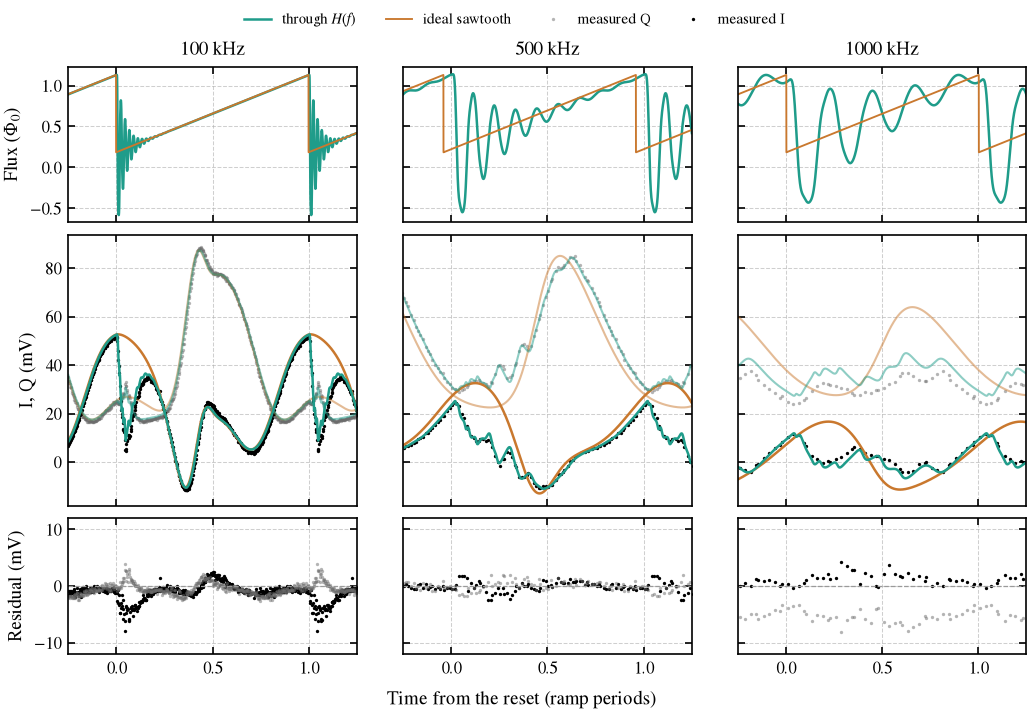

In [11]:
fig, axes = plt.subplots(3, len(TRACE_RATES), figsize=(DOUBLE, 4.8), sharex=True, sharey="row", gridspec_kw=HEIGHTS)
lims = []
for col, rate in zip(axes.T, TRACE_RATES):
    u_m, z_m = meas[rate]
    q = sims[rate, True].t * rate                                   # model phase from the reset
    q_ideal = q + shifts[rate, True] - shifts[rate, False]          # the ideal model at its own shift, in this frame
    lims.append(trace_column(col, rate, (u_m - shifts[rate, True]) % 1, z_m, q, A * sims[rate, True].s21 + B,
                             ramp_flux(rate, True, PHI_RESET)(q / rate), ramp_flux(rate, False, PHI_RESET)(q_ideal / rate),
                             A * models[rate, False](q_ideal) + B))
axes[2, 0].set_ylim(-max(lims), max(lims))
fig.supxlabel("Time from the reset (ramp periods)", fontsize=9)
finish(fig, axes)
save(fig, "06_traces_vs_rate", RESULTS / "figures")
plt.show()

At 100 kHz the ideal ramp misses the dip and ringing after every reset, which the model through $H(f)$ follows. At
500 kHz the line rings through the whole period and the measured wiggles are the coil's ringing, traced out by the
resonator. At 1 MHz the period is about two ring-up times and 2.5 decay times of the line, so neither the resonator nor the
coil ever settles; the shape is still followed, but the measured $Q$ sits below the model by a nearly constant amount
(Step 7).

The same comparison in the IQ plane, in the style of Fig. 10: the measured loop (black), the $H(f)$ model (teal) and the
quasi-static trajectory $A\,S_{21}(\Phi_\mathrm{reset} + 0.946\,u) + B$ (dashed) that an infinitely slow ramp would
trace along the resonance circle. The alignment plays no role here.

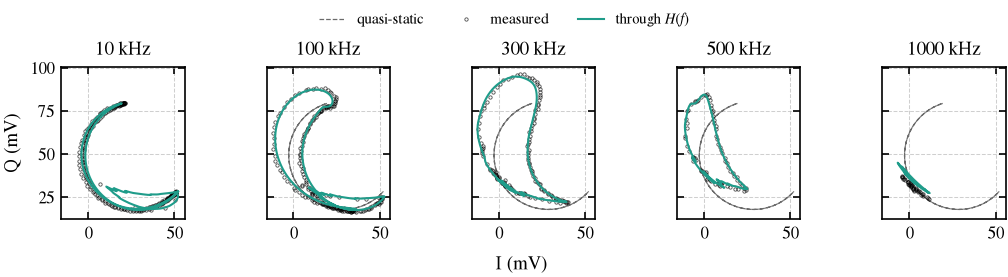

In [12]:
q = np.linspace(0, 1, 2000)
z_qs = A * static(PHI_RESET + RAMP_AMP * q) + B

fig, axes = plt.subplots(1, len(IQ_RATES), figsize=(DOUBLE, 1.9), sharex=True, sharey=True)
for ax, rate in zip(axes, IQ_RATES):
    u_m, z_m = meas[rate]
    step = max(1, len(z_m) // 200)                                  # at most ~200 measured points per loop
    z_tf = A * sims[rate, True].s21 + B
    ax.plot(z_qs.real * 1e3, z_qs.imag * 1e3, color=GRAY, ls="--", lw=0.6, label="quasi-static")
    ax.plot(z_m.real[::step] * 1e3, z_m.imag[::step] * 1e3, "o", color=MEASURED, ms=1.6, mfc="none", mew=0.4,
            alpha=0.7, label="measured")
    ax.plot(z_tf.real * 1e3, z_tf.imag * 1e3, color=MODEL_TF, lw=1.0, label="through $H(f)$")
    ax.set_title(f"{rate / 1e3:g} kHz")
    ax.set_aspect("equal")
    grid(ax)
axes[0].set_ylabel("Q (mV)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=7)
fig.supxlabel("I (mV)", fontsize=9)
save(fig, "06_iq_plane_vs_rate", RESULTS / "figures")
plt.show()

At 10 kHz the loop is the quasi-static arc with a short excursion after the reset. As the rate rises the resonator lags
the flux and the coil's ringing is traced out after each reset, so the loop opens and moves off the resonance circle;
at 1 MHz only a small loop remains, offset from the prediction.

## 7. Residuals at every rate (Table III)

Every rate above 1 kHz is out of sample: the device, $A$, $B$ and $\Phi_\mathrm{reset}$ are frozen, and only the time
shift is found per record. All columns are rms $|z_\mathrm{meas} - z_\mathrm{model}|$ in units of the 1 kHz excursion.

- **H(f)**: the full model, the CMT driven through $H(f)$.
- **offset rm**: the same residual with its mean subtracted, which amounts to refitting the offset $B$ for that record
  alone (two more real numbers per record): a diagnostic of the shape, not a prediction.
- **ideal**: the CMT driven by the ideal sawtooth, at its own best shift; the difference to **H(f)** is what the bias
  line contributes.
- **noise**: the noise of the 20-period average, half the rms difference of the even- and odd-period averages
  (`ramps.even_odd_noise`), the floor no model can go below.
- **q-static**: the static $S_{21}(\Phi)$ swept by the ideal ramp, at its own best shift. This is the size of the
  time-dependent signal, everything the measurement does that a static model misses.
- **H(f)/q-s**: the fraction of that time-dependent signal the full model leaves unexplained.

The summary splits at 500 kHz, the upper end of the band in which the paper validates $H(f)$ independently (Sec. IV C).

In [13]:
def quasi_static(q):
    "The static response swept by the ideal ramp, periodic in the phase from the reset."
    return static(PHI_RESET + RAMP_AMP * (np.asarray(q) % 1))


table = {}
for rate in rates[1:]:
    u_m, z_m = meas[rate]
    rec = records[rate]
    r = z_m - (A * models[rate, True](u_m - shifts[rate, True]) + B)
    noise = ramps.even_odd_noise(rec.z, rec.fs / rec.rate) / excursion
    err_qs = ramps.best_phase_shift(z_m, u_m, quasi_static, A, B, scale=excursion)[1]
    table[rate] = (resid[rate, True], ramps.rms_distance(r, r.mean(), excursion), resid[rate, False], noise, err_qs)

COLUMNS = ("H(f)", "offset rm", "ideal", "noise", "q-static", "H(f)/q-s")
print(f"{'rate (kHz)':>10}" + "".join(f"{c:>10}" for c in COLUMNS))
for rate, v in table.items():
    print(f"{rate / 1e3:10g}" + "".join(f"{x:10.1%}" for x in v) + f"{v[0] / v[4]:10.0%}")

summary = {}
for name, keep in (("10-500 kHz", lambda r: r <= 500e3), ("> 500 kHz", lambda r: r > 500e3)):
    v = np.array([table[r] for r in table if keep(r)])
    summary[name] = np.c_[v, v[:, 0] / v[:, 4]]
print(f"\n{'':18}" + "".join(f"{c:>10}" for c in COLUMNS))
for name, v in summary.items():
    print(f"{name:<11}{'median':>7}" + "".join(f"{x:10.1%}" for x in np.median(v, axis=0)))
    print(f"{'':<11}{'max':>7}" + "".join(f"{x:10.1%}" for x in np.max(v, axis=0)))
print(f"\n1 kHz calibration (in sample): {err_1k:.1%}")

err, _, err_ideal, noise, err_qs, unexplained = 100 * summary["10-500 kHz"].T
store.record("IQResMed", np.median(err), "{:.1f}", "median residual of the H(f) model, 10-500 kHz, % of the excursion (06)")
store.record("IQResMax", err.max(), "{:.1f}", "largest residual of the H(f) model, 10-500 kHz, % (06)")
store.record("IQNoiseMed", np.median(noise), "{:.1f}", "median noise of the folded records, 10-500 kHz, % (06)")
store.record("IQQsMed", np.median(err_qs), "{:.0f}", "median residual of the quasi-static model, 10-500 kHz, % (06)")
store.record("IQUnexplainedMed", np.median(unexplained), "{:.0f}", "median H(f) / quasi-static residual, 10-500 kHz, % (06)")
store.record("IQIdealMed", np.median(err_ideal), "{:.0f}", "median residual of the ideal-sawtooth model, 10-500 kHz, % (06)")
print("recorded:", ", ".join(f"{k} {store.text(k)}" for k in
                             ("IQResMed", "IQResMax", "IQNoiseMed", "IQQsMed", "IQUnexplainedMed", "IQIdealMed")))

rate (kHz)      H(f) offset rm     ideal     noise  q-static  H(f)/q-s
        10      4.8%      4.1%     12.6%      1.0%     12.8%       37%
        20      5.3%      4.5%     17.2%      1.7%     17.8%       29%
        40      5.3%      4.8%     23.5%      1.6%     25.1%       21%
        50      5.3%      5.0%     26.3%      1.7%     28.4%       19%
        60      6.1%      5.6%     28.1%      1.5%     30.7%       20%
        70      5.7%      5.6%     31.0%      1.4%     34.1%       17%
        80      6.6%      5.4%     33.9%      1.6%     37.3%       18%
        90      6.4%      5.9%     34.5%      1.4%     38.7%       17%
       100      7.0%      6.1%     38.5%      1.6%     42.9%       16%
       110      7.0%      5.9%     40.3%      1.4%     45.3%       15%
       120      8.0%      6.2%     42.9%      1.5%     48.6%       16%
       140      6.7%      6.5%     44.8%      1.6%     51.6%       13%
       150      8.7%      7.3%     48.2%      1.4%     55.7%       16%
      

From 10 to 500 kHz the frozen model follows the records to a median of 6.5% of the excursion (at most 10.1%), against a
noise floor of 1.6%. The quasi-static model misses by a median of 47% and the CMT driven by the ideal sawtooth by 42%,
so the resonator's lag alone explains little of the time-dependent signal and the ringing of the bias line most of it;
the full model leaves a median of 16% unexplained.

Above 500 kHz the residual grows and varies from record to record with no trend (5.5-19% from 600 kHz to 1.5 MHz, 39% at
2 MHz) while the noise does not. Most of the excess is a constant offset in the IQ plane: with the offset removed every
rate above 500 kHz falls to 3-8%, so the shape of the response is still reproduced. The source of the offset has not
been identified. The digitizer's analog anti-alias low-pass, which is not in the model, has unit gain at DC and cannot
move the mean of a trace, but it does round the fastest features, and at 2 MHz a period spans only 20 samples.

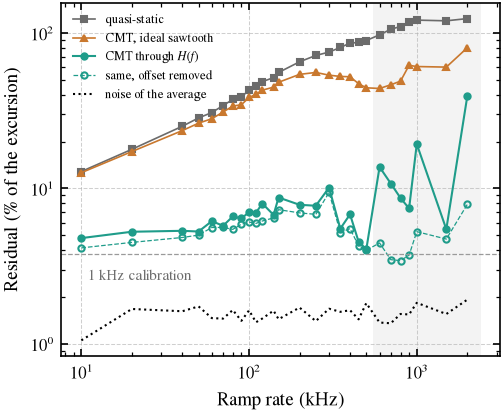

In [14]:
r_khz = np.array(list(table)) / 1e3
err, err_flat, err_ideal, noise, err_qs = 100 * np.array(list(table.values())).T

fig, ax = plt.subplots(figsize=(SINGLE, 2.8))
ax.loglog(r_khz, err_qs, "s-", color=GRAY, ms=3, lw=0.8, label="quasi-static")
ax.loglog(r_khz, err_ideal, "^-", color=MODEL_IDEAL, ms=3, lw=0.8, label="CMT, ideal sawtooth")
ax.loglog(r_khz, err, "o-", color=MODEL_TF, ms=3, lw=1.0, label="CMT through $H(f)$")
ax.loglog(r_khz, err_flat, "o--", color=MODEL_TF, ms=3, mfc="none", lw=0.6, label="same, offset removed")
ax.loglog(r_khz, noise, ":", color=MEASURED, lw=1.0, label="noise of the average")
ax.axhline(100 * err_1k, color=ZERO, ls="--", lw=0.6)
ax.text(11, 100 * err_1k * 0.8, "1 kHz calibration", color=GRAY, fontsize=7, va="top")
ax.axvspan(550, 2400, color=GRAY, alpha=0.08, lw=0)
ax.set_xlabel("Ramp rate (kHz)")
ax.set_ylabel("Residual (% of the excursion)")
ax.legend(loc="upper left", fontsize=6)
grid(ax)
save(fig, "06_residual_vs_rate", RESULTS / "figures")
plt.show()

## 8. Run time

The cost of `simulate` is set by the simulated time, 5 $\mu$s of settling plus one period, resolved in steps of at most
20 ns: a 1 kHz period takes several seconds, and every rate from 100 kHz up a fraction of a second, where the settling
dominates. Driving through $H(f)$ costs somewhat more than the ideal ramp, since the solver has to resolve the ringing.
One fresh run of each case, timed with `time.perf_counter`; the cell takes about 20 s.

In [15]:
T_RATES = [1e3, 10e3, 100e3, 500e3, 1e6, 2e6]
timing = {}
for rate in T_RATES:
    for use_tf in (False, True):
        t0 = time.perf_counter()
        simulate(rate, use_tf, PHI_RESET)
        timing[rate, use_tf] = time.perf_counter() - t0

print(f"{'rate (kHz)':>10} {'simulated (us)':>15} {'ideal (s)':>10} {'H(f) (s)':>9}")
for rate in T_RATES:
    print(f"{rate / 1e3:10g} {(5e-6 + 1 / rate) * 1e6:15.1f} {timing[rate, False]:10.2f} {timing[rate, True]:9.2f}")

per_ms = timing[1e3, True] / (1e3 * (5e-6 + 1e-3))
fast = max(timing[rate, True] for rate in T_RATES if rate >= 100e3)
print(f"\nthrough H(f): {per_ms:.1f} s per simulated ms; every rate from 100 kHz up in at most {fast:.2f} s")
store.record("IQTimeOneK", timing[1e3, True], "{:.1f}", "wall time of one 1 kHz period through H(f), s (06)")
store.record("IQTimePerMs", per_ms, "{:.1f}", "wall time per simulated millisecond through H(f), s (06)")
store.record("IQTimeFast", fast, "{:.2f}", "longest wall time of one period at 100 kHz-2 MHz through H(f), s (06)")
print("recorded:", ", ".join(f"{k} {store.text(k)}" for k in ("IQTimeOneK", "IQTimePerMs", "IQTimeFast")))

rate (kHz)  simulated (us)  ideal (s)  H(f) (s)
         1          1005.0       6.07      7.35
        10           105.0       0.62      0.74
       100            15.0       0.09      0.14
       500             7.0       0.20      0.26
      1000             6.0       0.33      0.38
      2000             5.5       0.59      0.62

through H(f): 7.3 s per simulated ms; every rate from 100 kHz up in at most 0.62 s
recorded: IQTimeOneK 7.4, IQTimePerMs 7.3, IQTimeFast 0.62


## What to try next

* **Perturb a fixed input.** The ramp amplitude is measured at the source, not fitted. Set `RAMP_AMP = 1.0`, the nominal
  ramp, in the first cell and rerun: the scan moves to $\Phi_\mathrm{reset} = 0.158$ and the 1 kHz record is fitted
  worse (0.043), yet the 10-500 kHz median drops to 5.2%, so the predictions are sensitive to the amplitude at the level
  of their residual. The bias line matters far more: halving the Q of every mode,
  `tf = uc.FluxLineTF(2 * tf.poles.real + 1j * tf.poles.imag)` at the top of Step 6, more than triples the 10-500 kHz
  median (22%).
* **Use the other configuration.** `nist_res2_2026-10-04.toml` is the same resonator eight days later, with its bare
  frequency 0.38 MHz lower. Load it in Step 1 and rerun: the scan still returns a $\Phi_\mathrm{reset}$, but even the
  1 kHz record is fitted only to 0.38 of its excursion and every prediction misses by 40% or more. The records are from
  26 Sep, and only a characterisation of the same day describes them.
* **Your own records.** Any `.npz` with `I`, `Q` (V), `fs` and `f` (Hz) loads with `uc.load_record`; fold it with
  `ramps.fold_record` (with `from_resets=True` if the ramp does not run at its programmed rate), calibrate on your
  slowest record as in Step 5, and use the configuration (notebook `01`) and pole file (notebook `03`) of your own
  channel and bias line.